# 09 — R3 camera branch: Tier 1 and Tier 2

The same two easy flights and 1,312 windows are used throughout. Camera
preprocessing reads only window IDs/timestamps and images. Tier 1 reuses
Phase 1 Lasso tuning. E5 learns from three grayscale frames and uses R1's
purged validation split. Results below come from saved experiments, not
from test-flight hyperparameter selection.

Run `python scripts/verify_camera_data.py`, `python scripts/make_camera_features.py`,
and `python scripts/train_camera.py` from the project root first. Raw images
are only needed for verification and initial preprocessing. See
[the camera guide](../docs/camera_data.md) for formats and R4 integration.

In [1]:
from pathlib import Path
import sys
import json
ROOT = Path.cwd()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'src/vio_drift').is_dir(), 'Open from the repo or notebooks directory'
sys.path.insert(0, str(ROOT / 'src'))
from vio_drift.models.dl.camera_cnn import CameraCNN
from vio_drift.models.dl.train import parameter_count
from vio_drift.features.camera import feature_names
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
SEQUENCES = ['MH_01_easy', 'MH_02_easy']
P = ROOT / 'data/processed'
display(pd.read_csv(ROOT / 'results/diagnostics/camera_data_check.csv'))

,seq_id,status,n_frames,n_windows,images_opened,nominal_rate_hz,median_rate_hz,mean_rate_hz,max_frame_gap_ms,min_frames_per_window,max_frames_per_window,width,height
0,MH_01_easy,ok,3682,720,3682,20,20.000051,20.0,50.000128,40,40,752,480
1,MH_02_easy,ok,3040,592,3040,20,19.999949,20.0,50.000128,40,40,752,480


## Image inputs and window alignment

Start and end mean the first/last frames **inside** `[t_start_ns, t_end_ns)`.
The middle frame is nearest the temporal midpoint. Channel order is temporal,
not RGB. The following checks verify all window rows using small artifacts.

,sequence,windows,shape,MiB
0,MH_01_easy,720,"(720, 3, 64, 64)",8.4375
1,MH_02_easy,592,"(592, 3, 64, 64)",6.9375


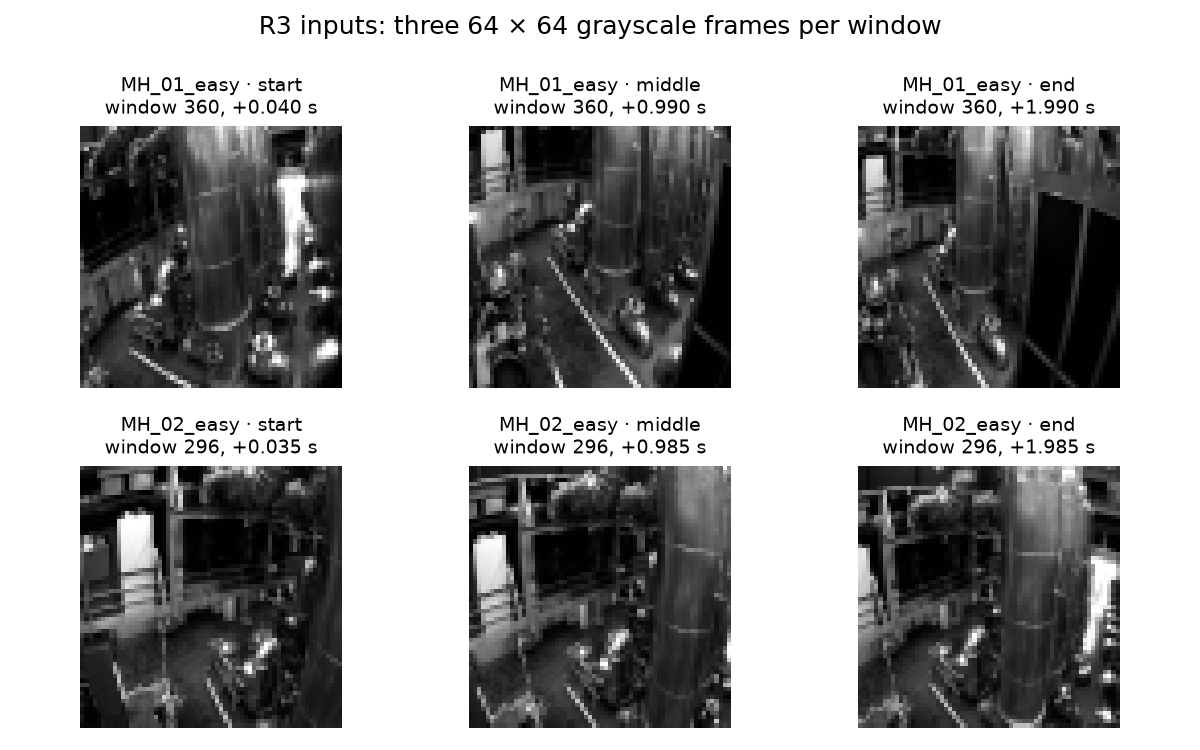

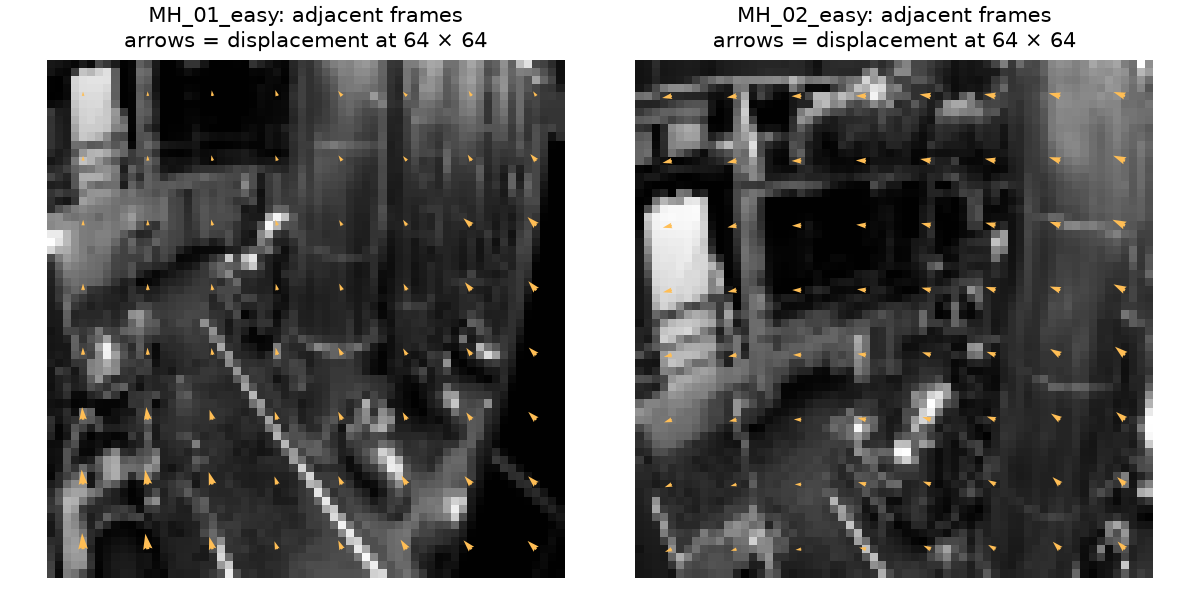

In [2]:
rows = []
for seq in SEQUENCES:
    windows = pd.read_csv(P / f'windows_{seq}.csv')
    features = pd.read_csv(P / 'camera' / f'camera_feats_{seq}.csv')
    camera = np.load(P / 'camera' / f'cam_{seq}.npy', mmap_mode='r', allow_pickle=False)
    index = pd.read_csv(ROOT / 'data/interim/camera' / f'frame_index_{seq}.csv')
    assert features[['seq_id', 'window_id']].equals(windows[['seq_id', 'window_id']])
    assert camera.shape == (len(windows), 3, 64, 64) and camera.dtype == np.uint8
    chosen = index.timestamp_ns.to_numpy()[features[['frame_start', 'frame_middle', 'frame_end']].to_numpy()]
    assert (chosen >= windows.t_start_ns.to_numpy()[:, None]).all()
    assert (chosen < windows.t_end_ns.to_numpy()[:, None]).all()
    rows.append({'sequence': seq, 'windows': len(windows), 'shape': str(camera.shape), 'MiB': camera.nbytes / 2**20})
display(pd.DataFrame(rows))
display(Image(filename=str(ROOT / 'figures/dl/camera_samples.png')))
display(Image(filename=str(ROOT / 'figures/dl/camera_flow_examples.png')))

## Tier 1 — refit the same Lasso with and without ten image features

`fit_model('lasso', ...)` from the existing Phase 1 code selects alpha using
five purged time blocks of the training flight and its median-MAE rule.
The final scaler and regression fit see the whole training flight; the other
flight is evaluated only after fitting. The feature allowlist excludes
window IDs, timestamps, frame counts and frame indices.

This cell can rerun both experiments using the same implementation. Keep it
off to inspect saved results quickly; smoke runs can use `--output-dir` to
avoid replacing reported outputs.

In [3]:
RUN_EXPERIMENTS = False
if RUN_EXPERIMENTS:
    import subprocess
    subprocess.run([sys.executable, str(ROOT / 'scripts/train_camera.py')], cwd=ROOT, check=True)
print('Camera predictors:', feature_names())
tier1 = pd.read_csv(ROOT / 'results/diagnostics/camera_tier1_check.csv')
display(tier1)
comparison = tier1.pivot(index='fold_id', columns='model', values='mae') * 100
comparison['camera_minus_baseline_cm'] = comparison['lasso_camera'] - comparison['lasso']
display(comparison)
print('Equal-fold mean MAE (cm):')
display(tier1.groupby('model')[['mae', 'rmse', 'bias']].mean() * 100)
cv = pd.read_csv(ROOT / 'results/diagnostics/camera_tier1_cv.csv')
assert set(cv.fold_id) == set(tier1.fold_id)
assert len(cv) == 64
# Reproduces the existing Phase 1 baseline without modifying its result files.
phase1 = pd.read_csv(ROOT / 'results/metrics/err_mag_m.csv')
print('Tier 1 alpha choices come only from the training-flight CV table.')

Camera predictors: ['flow_mag_mean', 'flow_mag_std', 'flow_mag_p90_mean', 'flow_dx_mean', 'flow_dy_mean', 'flow_dx_std', 'flow_dy_std', 'blur_mean', 'blur_std', 'corners_mean']


,fold_id,model,use_camera,n_features,n_train,n_test,alpha,mae,rmse,r2,bias
0,leave_MH_01_easy,lasso,False,104,592,720,0.002154,0.025932,0.032797,0.675833,-0.000404
1,leave_MH_01_easy,lasso_camera,True,114,592,720,0.001000,0.026164,0.032951,0.672786,-0.000942
2,leave_MH_02_easy,lasso,False,104,720,592,0.000464,0.024157,0.031751,0.836593,-0.001980
3,leave_MH_02_easy,lasso_camera,True,114,720,592,0.100000,0.046532,0.079415,-0.022253,0.011717


model,lasso,lasso_camera,camera_minus_baseline_cm
fold_id,,,
leave_MH_01_easy,2.59320,2.616408,0.023208
leave_MH_02_easy,2.41575,4.653250,2.237500


Equal-fold mean MAE (cm):


,mae,rmse,bias
model,,,
lasso,2.504475,3.227406,-0.119216
lasso_camera,3.634829,5.618305,0.538743


Tier 1 alpha choices come only from the training-flight CV table.


## Tier 2 — camera-only CNN (E5)

Three Conv2d → GroupNorm → ReLU → Dropout2d blocks use channels 16, 32, 64,
3 × 3 kernels and stride 2. Global average pooling yields a 64-number
embedding. R2's shared linear regression head gives one magnitude or four
outputs; E5 trains only magnitude. GroupNorm needs no batch-statistics refresh.

AdamW, weight decay, dropout, a validation plateau schedule and early stopping
use the unchanged DL defaults. Test windows cannot select checkpoints.
Each fold uses the last 20% of its training flight for validation with a 4 s
gap; the test flight is unseen during fitting. Seeds 42, 43, 44 are reported
separately, then with sample standard deviation.

In [4]:
import torch
model = CameraCNN().eval()
assert model.encode(torch.zeros(2, 3, 64, 64)).shape == (2, 64)
print('Encoder parameters:', parameter_count(model.encoder))
print('Full E5 parameters:', parameter_count(model))
e5 = pd.read_csv(ROOT / 'results/metrics/camera_e5.csv')
display(e5)
summary = pd.read_csv(ROOT / 'results/metrics/camera_e5_summary.csv')
display(summary)
# First average folds within each seed; then calculate seed spread.
equal_fold = e5.groupby('seed')[['test_mae', 'test_rmse', 'test_r2', 'test_bias']].mean()
display(equal_fold)
print('Equal-fold MAE mean ± seed SD (cm):', equal_fold.test_mae.mean() * 100, equal_fold.test_mae.std() * 100)
for row in e5.itertuples(index=False):
    exp = 'E5' if row.seed == 42 else f'E5_seed{row.seed}'
    pred = pd.read_csv(ROOT / 'results/predictions' / f'{exp}_{row.fold_id}.csv')
    assert pred.columns.tolist() == ['seq_id', 'window_id', 'y_true', 'y_pred']
    assert len(pred) == row.n_test and np.isfinite(pred.y_pred).all()

Encoder parameters: 23808
Full E5 parameters: 23873


,experiment,fold_id,seed,parameters,n_train,n_validation,n_test,epochs_ran,best_epoch,best_val_loss,best_val_mae_m,test_mae,test_rmse,test_r2,test_bias
0,E5,leave_MH_01_easy,42,23873,450,119,720,26,11,0.000440,0.017172,0.039112,0.055959,0.056271,0.003829
1,E5,leave_MH_01_easy,43,23873,450,119,720,26,11,0.000532,0.018952,0.037421,0.055844,0.060159,0.008773
2,E5,leave_MH_01_easy,44,23873,450,119,720,33,18,0.000587,0.019506,0.037179,0.052008,0.184836,0.003458
3,E5,leave_MH_02_easy,42,23873,553,144,592,39,24,0.001253,0.028136,0.050770,0.078059,0.012367,-0.000291
4,E5,leave_MH_02_easy,43,23873,553,144,592,55,40,0.001125,0.026744,0.048307,0.075775,0.069311,0.001212
5,E5,leave_MH_02_easy,44,23873,553,144,592,32,17,0.001336,0.028545,0.052529,0.076140,0.060332,-0.006546


,fold_id,test_mae_mean,test_mae_std,test_rmse_mean,test_rmse_std,test_r2_mean,test_r2_std,test_bias_mean,test_bias_std,n_seeds
0,leave_MH_01_easy,0.037904,0.001053,0.054604,0.002249,0.100422,0.073131,0.005353,0.002968,3
1,leave_MH_02_easy,0.050536,0.002121,0.076658,0.001227,0.047336,0.030616,-0.001875,0.004115,3


,test_mae,test_rmse,test_r2,test_bias
seed,,,,
42,0.044941,0.067009,0.034319,0.001769
43,0.042864,0.065810,0.064735,0.004993
44,0.044854,0.064074,0.122584,-0.001544


Equal-fold MAE mean ± seed SD (cm): 4.421971517953429 0.11747758649142664


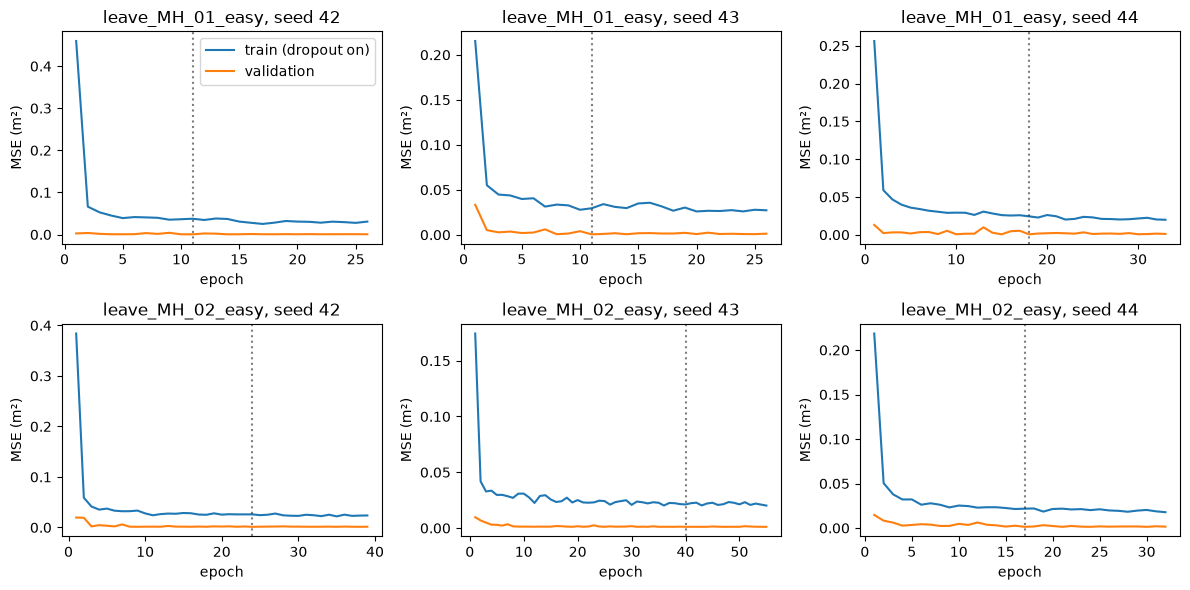

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6), squeeze=False)
for row_idx, fold in enumerate(sorted(e5.fold_id.unique())):
    for col_idx, seed in enumerate(sorted(e5.seed.unique())):
        exp = 'E5' if seed == 42 else f'E5_seed{seed}'
        history = pd.read_csv(ROOT / 'results/metrics' / f'{exp}_{fold}_loss.csv')
        ax = axes[row_idx, col_idx]
        ax.plot(history.epoch, history.train_loss, label='train (dropout on)')
        ax.plot(history.epoch, history.val_loss, label='validation')
        selected = e5[(e5.fold_id == fold) & (e5.seed == seed)].iloc[0]
        ax.axvline(selected.best_epoch, color='black', ls=':', alpha=0.5)
        ax.set(title=f'{fold}, seed {seed}', xlabel='epoch', ylabel='MSE (m²)')
axes[0, 0].legend()
fig.tight_layout()
plt.show()

## Interpretation and handoff

A negative `camera_minus_baseline_cm` is an improvement for Tier 1 on that
fold. It is not a fusion result. E5 tests the standalone learned image
representation; R4/R5 still own E6 and A3, which determine whether camera
embeddings help the IMU model. Three seeds quantify optimisation variability,
not generalisation uncertainty across flights.

The E5 and Lasso training counts differ because E5 reserves a validation
block and purge, whereas the Phase 1 Lasso protocol refits on the whole
training flight. The reported overall scores average folds equally; R² is
never computed by pooling flights. Images and blur/corner measures can encode
scene appearance. Neither flow nor CNN embeddings are guaranteed to capture
metric motion or IMU bias.

For H3, import `CameraCNNEncoder` and concatenate its `(B,64)` output with the
IMU embedding. For E7, join `feature_names()` by `seq_id, window_id` and fit
any scaler only on eligible training rows. R1/R2 production code and artifacts
remain unchanged. The label/physics ground-truth-initialisation caveat from
Phase 1 still applies.